# Experiment 1: attractors and chaos

**Question.** Starting from random "soups" on a torus, how long does Conway's Game of Life wander before it falls into a cycle (the *transient*), what kind of cycle does it end on (the *period*), and how do both change with the grid size $L$?

Part 1a measures transients, part 1b the distribution of periods. Part 1c asks how sensitive the outcome is to flipping a single initial cell.

## Predictions (written before any run)

| # | Question | Prediction |
|---|---|---|
| 1 | Typical transient on a 64 × 64 torus, density 0.35 | ~10 000 generations |
| 2 | Transient when $L$ doubles from 64 to 128 | grows like $L^2$ |
| 3 | Most common period; very long periods? | around 100; very long periods are rare |
| 4 | Fraction of single-cell flips that end on the same attractor | ~1 in 1000 |
| 5 | Growth of the damage $d(t)$ under Life | grows, then levels off (S-shaped); HighLife and Seeds: no prediction |
| 6 | Any run not settling within 20 000 generations? | none |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from life.metrics import detect_cycle
from life.rules import CONWAY
from life.topology import Lattice

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
DATA = ROOT / "data" / "exp01"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

DENSITY = 0.35
MAX_STEPS = 20_000
RUNS = {16: 200, 32: 200, 64: 200, 128: 50}
TORUS = Lattice("torus")

## 1a. Transient length and period

For each grid size $L$, draw random initial states (each cell alive with probability 0.35, seeds 0, 1, 2, …) and run `detect_cycle` with a cap of 20 000 generations. A run that hits the cap is recorded as *censored*, not dropped.

In [2]:
records = []  # (L, seed, transient, period); -1 marks a censored run
for size, n_runs in RUNS.items():
    start = time.perf_counter()
    for seed in range(n_runs):
        soup = np.random.default_rng(seed).random((size, size)) < DENSITY
        cycle = detect_cycle(soup, CONWAY, TORUS, max_steps=MAX_STEPS)
        if cycle is None:
            records.append((size, seed, -1, -1))
        else:
            records.append((size, seed, cycle.transient, cycle.period))
    print(f"L = {size:>3}: {n_runs} runs in {time.perf_counter() - start:.1f} s")

results = np.array(records, dtype=np.int64)
np.savetxt(
    DATA / "cycles.csv",
    results,
    fmt="%d",
    delimiter=",",
    header="L,seed,transient,period",
    comments="",
)

L =  16: 200 runs in 1.2 s
L =  32: 200 runs in 5.8 s
L =  64: 200 runs in 31.8 s
L = 128: 50 runs in 55.9 s


In [3]:
print(f"{'L':>4} {'runs':>5} {'censored':>9} {'median':>8} {'mean':>8} {'p90':>8} {'max':>8}")
for size in RUNS:
    rows = results[results[:, 0] == size]
    done = rows[rows[:, 2] >= 0, 2]
    print(
        f"{size:>4} {len(rows):>5} {np.sum(rows[:, 2] < 0):>9} {np.median(done):>8.0f} "
        f"{done.mean():>8.0f} {np.percentile(done, 90):>8.0f} {done.max():>8}"
    )

   L  runs  censored   median     mean      p90      max
  16   200         0      110      136      262      528
  32   200         0      352      479     1048     2175
  64   200         0     1029     1266     2272     5481
 128    50         0     2404     2892     4984     7824


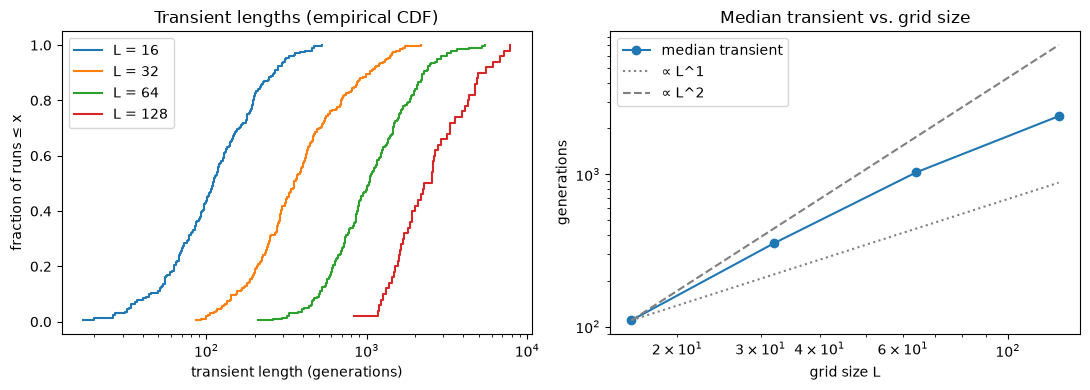

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

for size in RUNS:
    done = np.sort(results[(results[:, 0] == size) & (results[:, 2] >= 0), 2])
    left.step(done, np.arange(1, len(done) + 1) / len(done), where="post", label=f"L = {size}")
left.set_xscale("log")
left.set_xlabel("transient length (generations)")
left.set_ylabel("fraction of runs ≤ x")
left.set_title("Transient lengths (empirical CDF)")
left.legend()

sizes = np.array(list(RUNS))
medians = np.array(
    [np.median(results[(results[:, 0] == s) & (results[:, 2] >= 0), 2]) for s in sizes]
)
right.loglog(sizes, medians, "o-", label="median transient")
for power, style in [(1, ":"), (2, "--")]:
    right.loglog(
        sizes, medians[0] * (sizes / sizes[0]) ** power, style, color="grey", label=f"∝ L^{power}"
    )
right.set_xlabel("grid size L")
right.set_ylabel("generations")
right.set_title("Median transient vs. grid size")
right.legend()

fig.tight_layout()
fig.savefig(FIGURES / "exp01_transients.png", dpi=150)
plt.show()

## 1b. Which cycles do the soups end on?

In [5]:
done = results[results[:, 2] >= 0]
periods, counts = np.unique(done[:, 3], return_counts=True)
print("period : runs (all sizes)")
for p, c in zip(periods, counts, strict=True):
    print(f"{p:>6} : {c}")

print()
for size in RUNS:
    rows = done[done[:, 0] == size]
    values, n = np.unique(rows[:, 3], return_counts=True)
    print(f"L = {size:>3}: " + ", ".join(f"{v}×{k}" for v, k in zip(values, n, strict=True)))

period : runs (all sizes)
     1 : 141
     2 : 494
    64 : 5
   128 : 8
   256 : 2

L =  16: 1×112, 2×83, 64×5
L =  32: 1×28, 2×164, 128×8
L =  64: 1×1, 2×197, 256×2
L = 128: 2×50


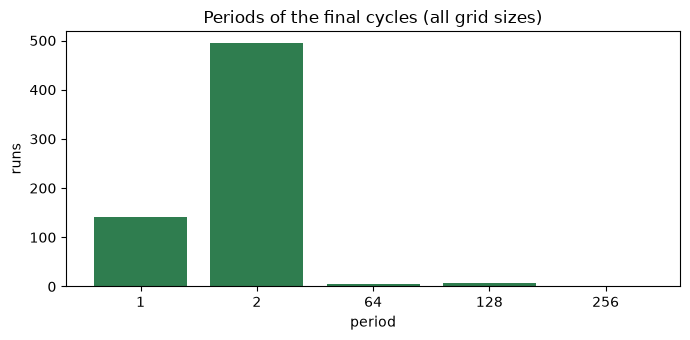

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([str(p) for p in periods], counts, color="#2f7d4f")
ax.set_xlabel("period")
ax.set_ylabel("runs")
ax.set_title("Periods of the final cycles (all grid sizes)")
fig.tight_layout()
fig.savefig(FIGURES / "exp01_periods.png", dpi=150)
plt.show()

## Results vs. predictions (1a, 1b)

| # | Prediction | Result |
|---|---|---|
| 1 | ~10 000 | Median 1029: off by a factor of ten. Most regions turn into still lifes and blinkers within a few hundred generations. |
| 2 | $\propto L^2$ | Between $L$ and $L^2$, with a falling slope; see puzzle C for why. |
| 3 | period ~100, long periods rare | Period 2 dominates (76 %) because the grid's period is the least common multiple of its objects' periods (puzzle B). Long periods are indeed rare (2.3 %) and come from gliders (puzzle A). |
| 6 | none censored | Correct: all 650 runs settled; the longest transient was 7824. |

## 1c. Damage spreading: how much does one flipped cell matter?

Take a soup, make a copy with **one cell flipped**, and run both with the same rule. The *damage* $d(t)$ is the number of cells in which the two runs differ at generation $t$, so $d(0) = 1$.

Three rules are compared on a 64 × 64 torus, 100 soups each (density 0.35), with the flipped cell chosen at random:

| Rule | Notation | Meaning |
|---|---|---|
| Life | B3/S23 | born with 3 live neighbours, survives with 2 or 3 |
| HighLife | B36/S23 | as Life, but also born with 6 |
| Seeds | B2/S | born with 2; no cell survives to the next generation |

In [7]:
from life.metrics import damage_spread, detect_cycle, flip
from life.rules import parse_rule

DAMAGE_SIZE = 64
DAMAGE_RUNS = 100
DAMAGE_STEPS = 1500
RULES = {"Life": "B3/S23", "HighLife": "B36/S23", "Seeds": "B2/S"}


def soup_and_cell(seed):
    rng = np.random.default_rng(10_000 + seed)
    soup = rng.random((DAMAGE_SIZE, DAMAGE_SIZE)) < DENSITY
    cell = tuple(int(x) for x in rng.integers(0, DAMAGE_SIZE, size=2))
    return soup, cell


damage = {}
for name, text in RULES.items():
    start = time.perf_counter()
    rule = parse_rule(text)
    damage[name] = np.array(
        [damage_spread(*soup_and_cell(s), DAMAGE_STEPS, rule, TORUS) for s in range(DAMAGE_RUNS)]
    )
    print(f"{name:>8}: {DAMAGE_RUNS} pairs in {time.perf_counter() - start:.1f} s")

np.savez_compressed(DATA / "damage.npz", **damage)

    Life: 100 pairs in 36.0 s
HighLife: 100 pairs in 36.0 s
   Seeds: 100 pairs in 36.0 s


In [8]:
cells_total = DAMAGE_SIZE**2
print(f"{'rule':>8} {'healed':>7} {'median d(100)':>14} {'median d(end)':>14} {'max d':>7}")
for name, d in damage.items():
    healed = np.mean(d[:, -1] == 0)
    print(
        f"{name:>8} {healed:>7.0%} {np.median(d[:, 100]):>14.0f} "
        f"{np.median(d[:, -1]):>14.0f} {d.max():>7}"
    )
print(f"(grid has {cells_total} cells)")

    rule  healed  median d(100)  median d(end)   max d
    Life      0%            670            268     986
HighLife      0%            836            172    1259
   Seeds     17%           1356           1358    1506
(grid has 4096 cells)


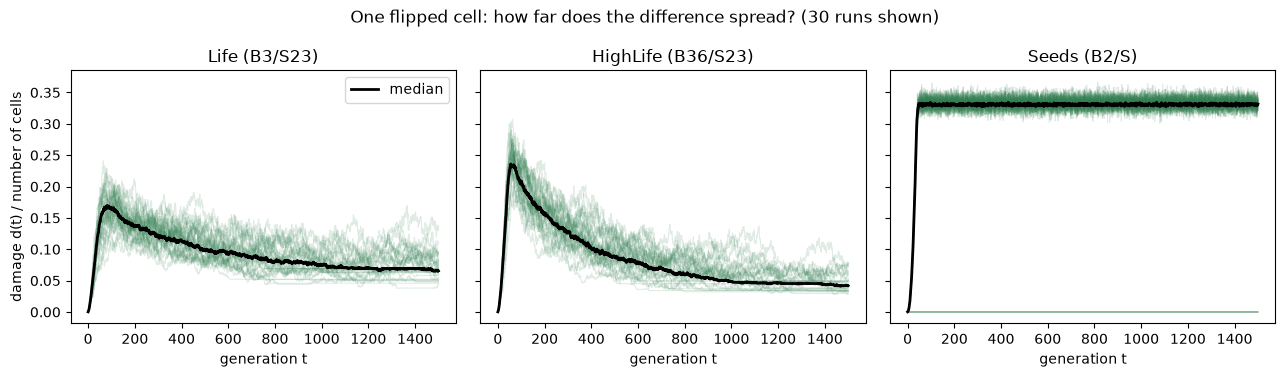

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
t = np.arange(DAMAGE_STEPS + 1)
for ax, (name, d) in zip(axes, damage.items(), strict=True):
    for row in d[:30]:
        ax.plot(t, row / cells_total, color="#2f7d4f", alpha=0.15, lw=0.8)
    ax.plot(t, np.median(d, axis=0) / cells_total, color="black", lw=2, label="median")
    ax.set_title(f"{name} ({RULES[name]})")
    ax.set_xlabel("generation t")
axes[0].set_ylabel("damage d(t) / number of cells")
axes[0].legend()
fig.suptitle("One flipped cell: how far does the difference spread? (30 runs shown)")
fig.tight_layout()
fig.savefig(FIGURES / "exp01_damage.png", dpi=150)
plt.show()

### Same final attractor?

For Life and HighLife, run both members of each pair to their final cycle and compare the attractors. Seeds is left out: its soups do not settle within the cap.

In [10]:
for name in ["Life", "HighLife"]:
    rule = parse_rule(RULES[name])
    same = differ = censored = 0
    for s in range(DAMAGE_RUNS):
        soup, cell = soup_and_cell(s)
        a = detect_cycle(soup, rule, TORUS, max_steps=MAX_STEPS)
        b = detect_cycle(flip(soup, cell), rule, TORUS, max_steps=MAX_STEPS)
        if a is None or b is None:
            censored += 1
        elif a.attractor == b.attractor:
            same += 1
        else:
            differ += 1
    print(f"{name:>8}: same attractor {same}, different {differ}, censored {censored}")

    Life: same attractor 0, different 100, censored 0
HighLife: same attractor 0, different 100, censored 0


### Watching the damage spread (Life)

Grey: live cells of the original run. Red: cells where the flipped run differs.

In [11]:
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

from life.engine import run

life = parse_rule(RULES["Life"])
soup, cell = soup_and_cell(0)
frames = 400
a = run(soup, frames, life, TORUS)
b = run(flip(soup, cell), frames, life, TORUS)
view = a.astype(np.uint8) + 2 * (a != b)  # 0 dead, 1 alive, 2 or 3 damaged

fig, ax = plt.subplots(figsize=(3.6, 3.9), dpi=100)
image = ax.imshow(
    view[0], cmap=ListedColormap(["#f4f5f6", "#9aa3ab", "#d1495b", "#d1495b"]), vmin=0, vmax=3
)
ax.set_xticks([])
ax.set_yticks([])
title = ax.set_title(f"Life · one flipped cell · t = {frames}", fontsize=9)
fig.tight_layout()


def update(i):
    image.set_data(view[i])
    title.set_text(f"Life · one flipped cell · t = {i}")
    return image, title


animation = FuncAnimation(fig, update, frames=range(0, frames + 1, 2))
animation.save(FIGURES / "exp01_damage.gif", writer=PillowWriter(fps=15))
plt.close(fig)
print("saved exp01_damage.gif")

saved exp01_damage.gif


## Results vs. predictions (1c)

| # | Prediction | Result |
|---|---|---|
| 4 | ~1 in 1000 end on the same attractor | 0 of 100 for both Life and HighLife. Consistent: with 100 pairs, a rate of 1 in 1000 would almost always show 0. One flipped cell is enough to change the final state completely. |
| 5 | Life: grows, then levels off (S-shaped) | Half right. It grows and levels off, but **overshoots**: it peaks around generation 80 and then declines to a plateau (puzzle F). HighLife behaves similarly; Seeds saturates almost immediately and never declines (puzzle G). |

What the output shows:

- **Life:** the damage grows quickly, peaks at about 17 % of the grid around generation 80, then falls slowly to about 7 % and stays there. It never heals.
- **HighLife:** the same shape with a higher, earlier peak (about 23 % around generation 55) and a lower plateau (about 4 %).
- **Seeds:** within about 40 generations the damage jumps to one third of the grid and stays there; 17 % of the pairs heal at once (at generation 1 or 2).
- **Same attractor:** in all 100 Life pairs and all 100 HighLife pairs, the flipped run ends on a **different** attractor than the original.

## Puzzles

The data did a few things that were not obvious in advance. Try each one before opening the answer.

**A. Long periods are exactly 64, 128 and 256, and each appears on only one grid size ($L$ = 16, 32, 64).**
*Hint: how many generations does a glider need to cross an $L \times L$ torus?*

<details><summary>Answer</summary>

All three equal $4L$. A glider moves one cell diagonally every 4 generations, so on an $L \times L$ torus it is back where it started after $4L$ generations. If a glider survives the transient, it circles forever and the whole grid has period $4L$. Replaying one of the period-64 runs on $L$ = 16 shows exactly that: its final cycle contains a single glider (5 live cells, 8 cells changing every 4 generations). On an infinite plane the glider would simply fly away, so these long periods are an artefact of the torus.
</details>

**B. The bigger the grid, the rarer period 1; on 128 × 128 every soup ends with period 2.**
*Hint: the grid's period depends on the period of every object on it.*

<details><summary>Answer</summary>

The period of the whole grid is the least common multiple of the periods of all objects on it. A single blinker (period 2) makes the whole grid period 2; period 1 requires that not one oscillator is left. A larger grid holds more objects, so "no oscillator at all" becomes very unlikely. A simple Poisson model fitted on $L$ = 16 (where 56 % of runs end with period 1) predicts 10 % for $L$ = 32 (observed 14 %) and essentially 0 for $L$ = 64 and 128 (observed 0.5 % and 0 %): the right trend, slightly underestimating the tail.
</details>

**C. Big grids never settle quickly: on 128 × 128 the shortest transient is 827 generations.**
*Hint: the grid is settled only when every region has settled.*

<details><summary>Answer</summary>

The transient of the whole grid is roughly the **maximum** of the transients of its regions. A 128 × 128 torus has the area of four 64 × 64 ones, so its transient behaves like the slowest of four. Drawing four transients from the $L$ = 64 results and taking the maximum (100 000 times) gives a median of 2042 and a 1st percentile of 764, against an observed median of 2404 and minimum of 827. The model explains most of the effect; the rest plausibly comes from interactions between regions (gliders and debris carrying activity elsewhere). Because a maximum grows slowly with the number of regions, it also explains why the transient grows more slowly than $L^2$.
</details>

**D. Period 3 never appears, although period-3 oscillators (such as the pulsar) exist.**
*Hint: what would the grid's period be with one pulsar and one blinker on it?*

<details><summary>Answer</summary>

A pulsar would make the grid's period 3, or 6 together with any blinker. Neither value appears, so none of the 650 final states (about 13 000 separate clusters of live cells in total) contains a period-3 oscillator. The pulsar has 48 cells and a high symmetry, and random soups rarely build it.
</details>

**F. Under Life the damage falls after its peak, yet the two runs never come back together.**
*Hint: compare the damage with the number of live cells in each run.*

<details><summary>Answer</summary>

At the end, the damage is almost exactly the number of live cells in the original run plus the number in the flipped run (for example 144 + 128 live cells against a damage of 264). So the two final states share almost nothing: they are completely different. The damage falls only because the soups themselves thin out from 35 % live cells to a few percent; with fewer live cells there are fewer cells that can differ. Measured relative to the number of live cells, the two runs stay fully decorrelated.
</details>

**G. Under Seeds the damage settles at almost exactly one third of the grid.**
*Hint: how different are two unrelated random grids with the same density of live cells?*

<details><summary>Answer</summary>

If two grids are independent and each cell is alive with probability $
ho$, they differ in a fraction $2
ho(1-
ho)$ of cells. Seeds settles at a live density of about $
ho = 0.211$, and $2 \cdot 0.211 \cdot 0.789 = 0.333$. So after about 40 generations the flipped run is as different from the original as an unrelated random grid: one cell has erased all memory of the starting state.
</details>

**H. Under Seeds 17 % of the pairs heal at once, but no pair heals later.**
*Hint: in Seeds every live cell dies at the next step. When can a flip change anything?*

<details><summary>Answer</summary>

The flipped cell itself never matters for long, since every live cell dies at the next step. What matters is whether the flip changes the fate of one of its 8 neighbours: a dead neighbour is born only with **exactly** 2 live neighbours, so the flip matters only if it moves a neighbour's count onto or off 2. When none of the neighbours is affected, the difference vanishes at generation 1; in one pair a single extra cell was born and died, so it vanished at generation 2. When the flip does change a birth that can feed further births, the difference spreads explosively and, in these runs, never disappeared again.
</details>

**E (open). No period 512 on the 128 × 128 torus.**

<details><summary>Current thinking</summary>

Not known. A glider survived in 2.5 %, 4 % and 1 % of the runs on $L$ = 16, 32 and 64. With a rate of 1–4 %, 50 runs would be expected to show 0.5–2 gliders; at 2 %, seeing none has a probability of about 36 %. So the absence may be chance. More runs on $L$ = 128, or a direct measurement of how often gliders are destroyed by debris on large grids, would settle it.
</details>

## Conclusions

- Random Life soups settle fast compared with the number of possible states: a typical 64 × 64 soup reaches its cycle after about 1000 generations, and the time grows more slowly than the area of the grid.
- The final state is almost always a mixture of still lifes and blinkers, so the grid's period is 2; long periods come from a glider circling the torus.
- The outcome is extremely sensitive to the initial state: flipping one cell in Life or HighLife changed the final attractor in every one of 200 pairs. Life is not "chaotic" in the sense of damage growing forever (the damage stays bounded by the shrinking number of live cells), but it never forgets a perturbation either. Seeds, by contrast, decorrelates completely within 40 generations.

Limitations and open questions: see the [write-up](../docs/experiments/01-attractors.md).